<h1 style="color:#274C77; font-family:Georgia,'Times New Roman',serif; font-size:32px; line-height:1.2; font-weight:600; margin:0 0 10px; padding-bottom:12px; border-bottom:1px solid #D7DEE5;">When Recalls Hit the Dealership</h1>
<p style="color:#0F766E; font-size:17px; margin:8px 0;">An NHTSA study of recall frequency, size, concentration, and predictability</p>
<p style="color:#64748B; font-size:13px; margin:0 0 20px;">Kirolos Boules · Data Science </p>

A recall can bring owners back to a dealership while also placing demands on appointments, parts, and technician time. I wanted to understand the patterns in reported recall activity and consider what they might mean for planning.

I organized the analysis around three questions:

| Question | Why it matters | Approach |
|:--|:--|:--|
| **01 · Who has frequent recalls, large campaigns, or both?** | Frequent small campaigns and occasional large campaigns may present different planning challenges. | Compare campaign counts and typical campaign sizes by brand. |
| **02 · How much do the biggest campaigns drive the totals?** | A typical campaign may hide the contribution of unusually large recalls. | Measure the share of reported affected units associated with the largest campaigns. |
| **03 · Does a learned model improve next month's recall-campaign forecast?** | Forecasting could help anticipate changes in activity if a model improves on a simple benchmark. | Compare a historical average with a random forest using earlier months only. |

**Scope.** I begin with the supplied NHTSA extract, select the **20 assignment brands**, and study **2013–2022**, the ten most recent complete years in this historical file. The analysis measures reported campaigns and affected populations; dealership visits and sales are not observed in these data.

## <span style="color:#274C77;">Data preparation · Establish a campaign-level dataset</span>

The source repeats recall information across makes, models, and model years. Counting these detail rows as campaigns would inflate frequency, and summing their repeated population values would inflate size. I first establish what each row represents, then create a dataset with **one row per campaign**.

I use Python and pandas for preparation, SQLite to aggregate campaigns by brand, Matplotlib for charts, and scikit-learn for forecasting.

In [1]:
from pathlib import Path
import csv
import re
import sqlite3
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import sklearn
from IPython.display import HTML, display
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import RandomForestRegressor

# The same restrained palette is used in headings, tables, and charts.
COLORS = {
    "navy": "#274C77", "teal": "#0F766E", "accent": "#C2410C",
    "ink": "#1F2937", "muted": "#64748B", "light": "#C7D8E2",
}
display(HTML("""
<style>
.jp-RenderedHTMLCommon, .rendered_html { font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Arial, sans-serif; font-size: 15px; line-height: 1.65; color: #1F2937; }
.jp-RenderedHTMLCommon h2, .rendered_html h2 { margin-top: 28px; padding-bottom: 9px; border-bottom: 1px solid #D7DEE5; font-size: 23px; line-height: 1.35; font-weight: 600; }
.jp-RenderedHTMLCommon h3, .rendered_html h3 { margin-top: 22px; font-size: 18px; line-height: 1.45; font-weight: 600; }
.jp-RenderedHTMLCommon p, .rendered_html p { margin: 10px 0 14px; }
.jp-RenderedHTMLCommon li, .rendered_html li { margin: 5px 0; }
.jp-RenderedHTMLCommon hr, .rendered_html hr { border: 0; border-top: 1px solid #D7DEE5; margin: 24px 0; }
.jp-RenderedHTMLCommon table, .rendered_html table { border-collapse: collapse; margin: 14px 0 20px; font-size: 13px; line-height: 1.55; border: none; background: transparent; }
.jp-RenderedHTMLCommon th, .rendered_html th { color: #274C77; font-weight: 600; border: none; border-bottom: 1px solid #A9BAC8; padding: 9px 12px; white-space: normal; vertical-align: bottom; background: transparent !important; }
.jp-RenderedHTMLCommon td, .rendered_html td { border: none; border-bottom: 1px solid #E3E8ED; padding: 8px 12px; vertical-align: top; font-variant-numeric: tabular-nums; background: transparent !important; }
.jp-RenderedHTMLCommon tbody tr, .rendered_html tbody tr { background: transparent !important; }
.report-table { width: auto; max-width: 100%; }
.report-table th { max-width: 185px; }
.report-table td { text-align: right; }
.jp-RenderedHTMLCommon .report-table tbody th, .rendered_html .report-table tbody th { text-align: left; color: #1F2937; border-bottom: 1px solid #E3E8ED; }
</style>
"""))

def show_table(frame, decimals=0, index=True):
    """Format a display copy; retain the original numeric values for analysis."""
    display_frame = frame.copy()
    formatters = {}
    for column in frame.columns:
        if pd.api.types.is_numeric_dtype(frame[column]):
            places = 0 if pd.api.types.is_integer_dtype(frame[column]) else decimals
            formatters[column] = lambda value, p=places: f"{value:,.{p}f}"
        if frame[column].isna().any():
            display_frame[column] = frame[column].astype(object).where(frame[column].notna(), np.nan)
    display(HTML(display_frame.to_html(
        index=index, border=0, classes="report-table", na_rep="—",
        formatters=formatters, escape=True,
    )))

available_fonts = {font.name for font in mpl.font_manager.fontManager.ttflist}
chart_font = next((name for name in ["Arial", "Liberation Sans", "DejaVu Sans"]
                   if name in available_fonts), "DejaVu Sans")
plt.rcParams.update({
    "font.family": chart_font, "font.size": 10.5,
    "figure.figsize": (10, 4), "figure.dpi": 120,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.titlesize": 12.5, "axes.titleweight": "semibold",
    "axes.titlecolor": COLORS["navy"], "axes.titlepad": 14,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#A8B5C1", "axes.linewidth": 0.8,
    "axes.labelcolor": COLORS["ink"], "text.color": COLORS["ink"],
    "xtick.color": COLORS["ink"], "ytick.color": COLORS["ink"],
    "legend.frameon": False, "legend.fontsize": 9.5,
    "grid.color": "#A8B5C1", "grid.linewidth": 0.7,
})
pd.set_option("display.max_columns", 12)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__}")

Python 3.12.14 | pandas 2.2.3 | scikit-learn 1.8.0


### <span style="color:#0F766E;">1A · Load the data and inspect the dictionary</span>

I check the row count, distinct campaign IDs, and whether the source columns agree with `RCL.txt`. Loading the raw fields as text preserves identifiers and lets me convert dates and counts explicitly.

**Source files:** the supplied NHTSA `FLAT_RCL.txt` and `RCL.txt`. The dictionary lists **29 fields**, while the extract contains **27**. The two later advisory fields, `DO_NOT_DRIVE` and `PARK_OUTSIDE`, are unavailable in this extract.

In [2]:
# Works when the files are inside ./data (usual layout) or beside this notebook.
folders = [Path("data"), Path(".")]

def find_source(filenames):
    for folder in folders:
        for filename in filenames:
            candidate = folder / filename
            if candidate.is_file():
                return candidate
    raise FileNotFoundError(
        f"Missing {filenames}. Put FLAT_RCL.txt and RCL.txt in a data folder."
    )

recall_file = find_source(["FLAT_RCL.txt", "FLAT_RCL(1).txt"])
dictionary_file = find_source(["RCL.txt", "RCL(2).txt"])

field_names = re.findall(
    r"^\s*\d+\s+([A-Z_]+)\s",
    dictionary_file.read_text(encoding="utf-8-sig"),
    flags=re.MULTILINE,
)
raw = pd.read_csv(
    recall_file, sep="\t", header=None, dtype="string",
    encoding="utf-8-sig", quoting=csv.QUOTE_NONE,
    keep_default_na=False,
)
if len(field_names) != 29 or raw.shape[1] not in (27, 29):
    raise ValueError("Unexpected field count: inspect the dictionary and raw data.")
raw.columns = field_names[:raw.shape[1]]

print(f"Source: {recall_file} | Dictionary: {dictionary_file}")
print(f"{len(raw):,} detail rows | {raw['CAMPNO'].nunique():,} distinct campaigns")
print(f"{raw.shape[1]} columns in data | {len(field_names)} in dictionary")
print("Unavailable dictionary fields:", field_names[raw.shape[1]:] or "None")
show_table(raw[["CAMPNO", "MAKETXT", "MODELTXT", "RCLTYPECD", "POTAFF", "RCDATE"]].head(4), index=False)

Source: data/FLAT_RCL.txt | Dictionary: data/RCL.txt
240,577 detail rows | 26,929 distinct campaigns
27 columns in data | 29 in dictionary
Unavailable dictionary fields: ['DO_NOT_DRIVE', 'PARK_OUTSIDE']


CAMPNO,MAKETXT,MODELTXT,RCLTYPECD,POTAFF,RCDATE
02V288000,FORD,FOCUS,V,291854,20021106
02V288000,FORD,FOCUS,V,291854,20021106
02V236000,JAYCO,FT EAGLE 10 SG,V,86,20020904
02V237000,HOLIDAY RAMBLER,ENDEAVOR,V,6223,20020909


### <span style="color:#0F766E;">1B · Clean the fields used in the analysis</span>

I trim whitespace, replace blank strings with missing values, and convert report dates and potentially affected units to appropriate types. **A reported zero remains distinct from a missing population.** The original `raw` table stays unchanged.

To identify repeated content, I compare **all original fields except `RECORD_ID`** after whitespace and blank-value cleanup. Sharing a `CAMPNO` alone does not make a detail row a duplicate: separate models and model years can legitimately belong to the same campaign. Campaign-level aggregation happens in the next step.

In [3]:
recalls = raw.copy()
for col in recalls.columns:
    recalls[col] = recalls[col].str.strip()
recalls = recalls.replace("", pd.NA)

# Keep distinct model / year / component records; drop only exact repeated content.
content_cols = raw.columns.drop("RECORD_ID")
duplicate_content = recalls.duplicated(subset=content_cols)
recalls = recalls.loc[~duplicate_content].copy()

recalls["report_date"] = pd.to_datetime(
    recalls["RCDATE"], format="%Y%m%d", errors="coerce"
)
recalls["potential_units"] = pd.to_numeric(recalls["POTAFF"], errors="coerce")

bad_dates = recalls["RCDATE"].notna() & recalls["report_date"].isna()
units = recalls["potential_units"]
bad_units = (
    recalls["POTAFF"].notna()
    & (units.isna() | units.lt(0) | units.mod(1).ne(0))
).fillna(False)
recalls.loc[bad_units, "potential_units"] = pd.NA

cleaning_check = pd.Series({
    "Source detail rows": len(raw),
    "Repeated content rows removed": int(duplicate_content.sum()),
    "Retained detail rows": len(recalls),
    "Missing campaign IDs": int(recalls["CAMPNO"].isna().sum()),
    "Unparseable report dates": int(bad_dates.sum()),
    "Missing reported populations": int(recalls["POTAFF"].isna().sum()),
    "Invalid populations": int(bad_units.sum()),
    "Reported zero populations": int(recalls["potential_units"].eq(0).sum()),
}, name="Rows")
show_table(cleaning_check.to_frame())

,Rows
Source detail rows,"240,577"
Repeated content rows removed,734
Retained detail rows,"239,843"
Missing campaign IDs,0
Unparseable report dates,0
Missing reported populations,289
Invalid populations,0
Reported zero populations,37


### <span style="color:#0F766E;">1C · Select brands and preserve campaign relationships</span>

- **Match the make.** I use `MAKETXT` for brand selection; `MFGNAME` identifies the company filing the report.
- **Standardize accepted names.** An explicit lookup groups variations such as `MERCEDES-BENZ` and `MERCEDES`. Labels such as `VOLVO BUS`, `HYUNDAI TRANSLEAD`, and `NISSAN DIESEL` remain outside the scope unless explicitly mapped. Their source rows remain in the cleaned data.
- **Check agreement before aggregation.** Across all detail rows belonging to selected campaigns, I check that populated report dates, recall types, and whole-campaign populations agree.
- **Build two related tables.** `campaigns` contains one row per `CAMPNO`; `campaign_brands` contains one row per campaign–brand connection. A campaign may involve several brands.
- **Combine consistent values.** `groupby().first()` retains the first nonmissing value for each field. It does not choose the newest record or add repeated populations.

I also confirm coverage of all **20 selected brands**.

In [4]:
selected_brands = [
    "BMW", "MINI", "MERCEDES", "LEXUS", "NISSAN", "AUDI",
    "VOLKSWAGEN", "HYUNDAI", "INFINITI", "KIA", "MAZDA",
    "LAND ROVER", "VOLVO", "HONDA", "JAGUAR", "ACURA",
    "TOYOTA", "MOPAR", "SUBARU", "PORSCHE",
]
brand_lookup = {name: name for name in selected_brands}
brand_lookup.update({
    "MERCEDES BENZ": "MERCEDES", "MERCEDES-BENZ": "MERCEDES",
    "MERCEDES-MAYBACH": "MERCEDES", "GULF TOYOTA": "TOYOTA",
    "HYUNDAI CARIBBEAN": "HYUNDAI", "HONDA GENUINE ACCESSORY": "HONDA",
    "FRAM/SUBARU": "SUBARU",
})
recalls["brand"] = recalls["MAKETXT"].str.upper().map(brand_lookup)
scoped_rows = recalls.loc[recalls["brand"].notna()].copy()

# Check campaign-level agreement across ALL rows for selected campaigns.
selected_ids = scoped_rows["CAMPNO"].dropna().unique()
campaign_fields = ["report_date", "RCLTYPECD", "potential_units"]
campaign_records = recalls.loc[
    recalls["CAMPNO"].isin(selected_ids), ["CAMPNO", *campaign_fields]
]
conflicts = (
    campaign_records.groupby("CAMPNO")[campaign_fields]
    .nunique(dropna=True).gt(1).any(axis=1)
)
if conflicts.any():
    raise ValueError("Conflicting campaign values: inspect the source before aggregating.")

campaigns = (
    campaign_records.groupby("CAMPNO", as_index=False)[campaign_fields]
    .first().rename(columns={"RCLTYPECD": "recall_type"})
)
campaign_brands = scoped_rows[["CAMPNO", "brand"]].drop_duplicates()

print(f"Selected makes: {scoped_rows['brand'].nunique()} | "
      f"Full-history campaigns: {len(campaigns):,} | "
      f"Campaign and brand links: {len(campaign_brands):,}")
print(f"Conflicting campaigns: {int(conflicts.sum())}")

Selected makes: 20 | Full-history campaigns: 4,449 | Campaign and brand links: 4,763
Conflicting campaigns: 0


### <span style="color:#0F766E;">1D · Set the study period and reconcile totals</span>

The supplied file ends during **2023**, so I exclude that partial year and use **2013–2022** as a consistent ten-year window. This is a scope choice, rather than a statistical requirement. Dates are indexed by `RCDATE`, when NHTSA received the report; customer notification and repair timing may differ.

I retain vehicle, equipment, child restraint, and tire recall codes wherever present. The selected period contains **2,065 vehicle campaigns and 55 equipment campaigns**, for **2,120 unique campaigns**. The category check confirms that none of the selected period's campaigns are discarded.

Vehicle and equipment populations are analyzed separately because their units are not interchangeable. A campaign involving several selected brands is counted once in the overall total and once for each associated brand in brand-level comparisons.

In [5]:
start_year, end_year = 2013, 2022
period_label = f"{start_year}–{end_year}"
category_names = {
    "V": "Vehicle", "E": "Equipment", "C": "Child restraint", "T": "Tire"
}

in_period = campaigns["report_date"].dt.year.between(start_year, end_year)
period_campaigns = campaigns.loc[in_period].copy()
analysis_recalls = period_campaigns.loc[
    period_campaigns["recall_type"].isin(category_names)
].copy()
brand_campaigns = campaign_brands.merge(
    analysis_recalls, on="CAMPNO", how="inner", validate="many_to_one"
)

# These checks make the key counting assumptions visible.
assert analysis_recalls["CAMPNO"].is_unique
assert not campaign_brands.duplicated(["CAMPNO", "brand"]).any()
assert len(period_campaigns) == len(analysis_recalls), "Unexpected category code"

coverage = (
    analysis_recalls["recall_type"].value_counts()
    .rename(index=category_names).rename("Unique campaigns").to_frame()
)
show_table(coverage.rename_axis("Category"))
print(f"{period_label}: {len(analysis_recalls):,} unique campaigns | "
      f"{len(brand_campaigns):,} campaign and brand links | "
      f"{brand_campaigns['brand'].nunique()} brands")

,Unique campaigns
Category,
Vehicle,"2,065"
Equipment,55


2013–2022: 2,120 unique campaigns | 2,257 campaign and brand links | 20 brands


## <span style="color:#274C77;">Question 01 · Who has frequent recalls, large campaigns, or both?</span>

**Why I chose it.** A dealership may face frequent small campaigns or occasional campaigns involving many vehicles. Looking at frequency alongside typical size gives a fuller picture of these different patterns.

**How I answer it.** I use SQL to count distinct campaigns by selected brand, then calculate the **median affected population** of each brand's vehicle campaigns with a positive reported population. The median describes a typical campaign while limiting the influence of unusually large populations.

For a campaign involving several brands, the population is the reported **whole-campaign value**. The extract does not allocate that population among the brands.

In [6]:
# SQL explicitly encodes the join and the counting grain.
with sqlite3.connect(":memory:") as conn:
    campaign_brands.to_sql("campaign_brands", conn, index=False)
    analysis_recalls[["CAMPNO", "recall_type"]].to_sql(
        "campaigns", conn, index=False
    )
    frequency = pd.read_sql_query("""
        SELECT b.brand,
               COUNT(DISTINCT c.CAMPNO) AS all_campaigns,
               COUNT(DISTINCT CASE WHEN c.recall_type = 'V'
                              THEN c.CAMPNO END) AS vehicle_campaigns
        FROM campaign_brands AS b
        JOIN campaigns AS c ON b.CAMPNO = c.CAMPNO
        GROUP BY b.brand
    """, conn)

vehicle_sizes = (
    brand_campaigns.loc[
        brand_campaigns["recall_type"].eq("V")
        & brand_campaigns["potential_units"].gt(0)
    ]
    .groupby("brand")
    .agg(size_observations=("CAMPNO", "nunique"),
         median_vehicle_units=("potential_units", "median"))
    .reset_index()
)
brand_summary = (
    frequency.merge(vehicle_sizes, on="brand", how="left", validate="one_to_one")
    .sort_values("all_campaigns", ascending=False).reset_index(drop=True)
)
brand_summary["size_observations"] = (
    brand_summary["size_observations"].fillna(0).astype(int)
)

show_table(brand_summary.set_index("brand").rename_axis("Brand").rename(columns={
    "all_campaigns": "All campaigns",
    "vehicle_campaigns": "Vehicle campaigns",
    "size_observations": "Vehicle campaigns with positive size",
    "median_vehicle_units": "Median affected units",
}).round(0))

,All campaigns,Vehicle campaigns,Vehicle campaigns with positive size,Median affected units
Brand,,,,
MERCEDES,387,387,387,550
BMW,229,223,223,"1,478"
TOYOTA,189,185,185,"11,807"
HONDA,156,148,147,"11,511"
VOLKSWAGEN,144,141,141,"3,184"
NISSAN,139,138,138,"12,916"
HYUNDAI,131,131,131,"18,700"
AUDI,131,130,130,"6,140"
KIA,97,97,97,"17,199"


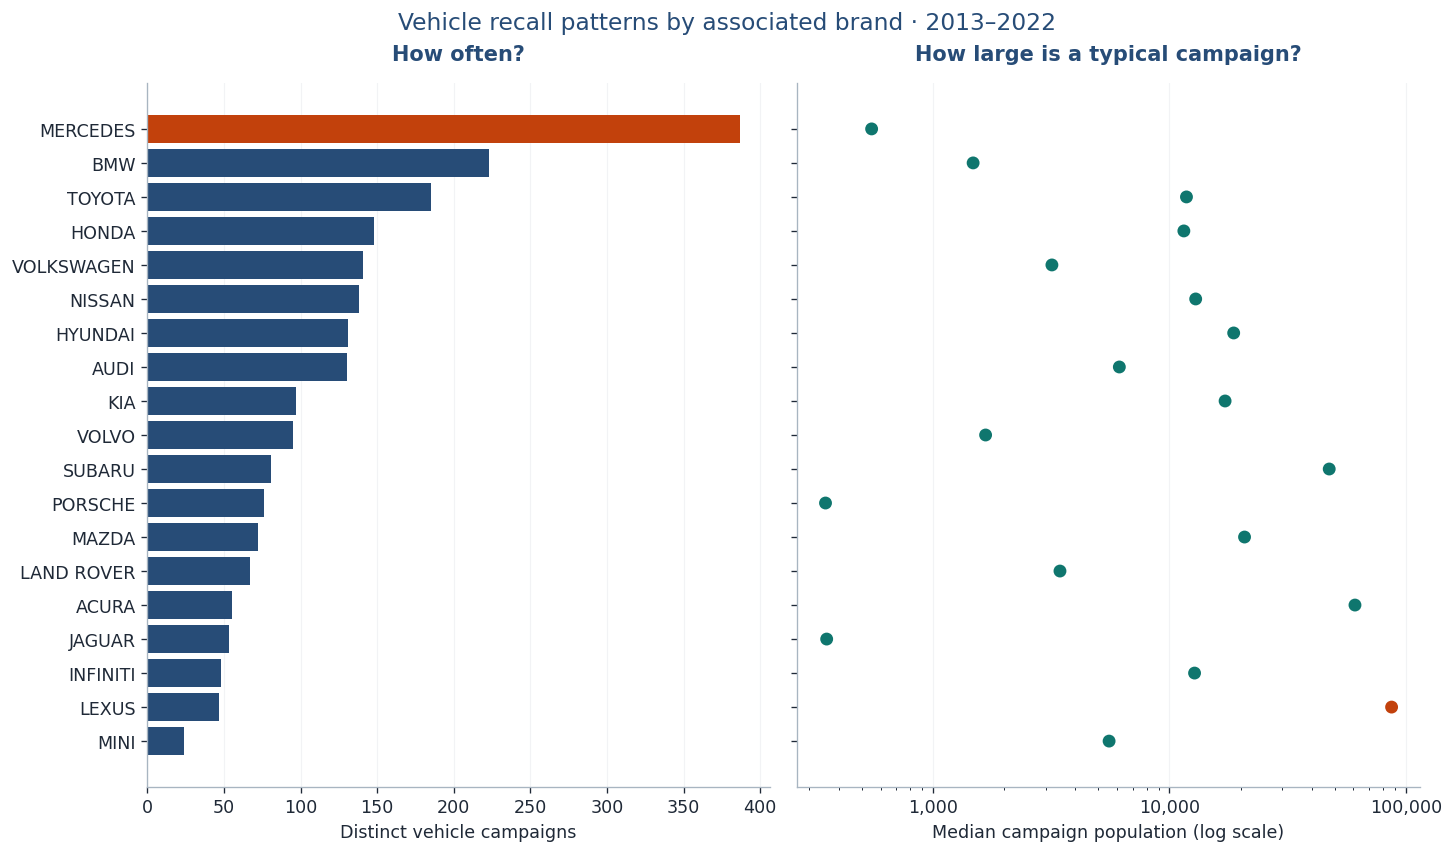

In [7]:
# Same brands, two different questions: frequency (bars) vs size (dots).
plot_data = brand_summary.loc[
    brand_summary["vehicle_campaigns"].gt(0)
].sort_values("vehicle_campaigns")

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True, layout="constrained")
axes[0].barh(
    plot_data["brand"], plot_data["vehicle_campaigns"],
    color=[COLORS["accent"] if b == "MERCEDES" else COLORS["navy"]
           for b in plot_data["brand"]],
)
axes[0].set(title="How often?", xlabel="Distinct vehicle campaigns")

axes[1].scatter(
    plot_data["median_vehicle_units"], plot_data["brand"], s=45,
    color=[COLORS["accent"] if b == "LEXUS" else COLORS["teal"]
           for b in plot_data["brand"]],
)
axes[1].set_xscale("log")
axes[1].set(title="How large is a typical campaign?",
            xlabel="Median campaign population (log scale)")
axes[1].xaxis.set_major_formatter(mpl.ticker.StrMethodFormatter("{x:,.0f}"))
for ax in axes:
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
fig.suptitle(f"Vehicle recall patterns by associated brand · {period_label}",
             fontsize=14, color=COLORS["navy"])
plt.show()

### <span style="color:#0F766E;">Answer 01 · Frequency and typical size tell different stories</span>

Among the selected brands during **2013–2022**, **Mercedes** has the most vehicle campaigns (**387**) and a median campaign population of **550**. **Lexus** has **47** vehicle campaigns and the largest median campaign population (**87,060**).

These patterns support tracking **campaign frequency and typical scale separately**. They do not establish comparative safety: the analysis lacks vehicles in service, sales volumes, repair participation, and individual brand shares of shared campaigns.

**MOPAR's 23 campaigns** are classified as equipment recalls, so it has no applicable vehicle-campaign median and does not appear on the vehicle chart.

### <span style="color:#0F766E;">A question prompted by the finding · Could smaller campaigns still create bottlenecks?</span>

**Could frequent, closely timed recalls create dealership bottlenecks despite their smaller typical campaign sizes?**

The contrast between Mercedes and Lexus prompted this question. Smaller individual campaigns could create manageable service demand, but several arriving close together could overlap before earlier repairs are finished.

- **What may change the outcome:** the timing of customer visits relative to available service capacity. Both manageable workloads and backlogs could occur at different points in the study period.
- **How I would investigate it:** examine Mercedes-specific campaign counts and affected populations over time, then connect periods of clustered activity to appointments, repair duration, parts availability, and technician capacity.
- **Connection to Question 03:** the forecast below predicts monthly campaign counts across all 20 brands. This follow-up would connect campaign timing to the more local question of when service capacity becomes strained.

This is an operational hypothesis; the recall extract does not measure dealership backlogs.

## <span style="color:#274C77;">Question 02 · How much do the biggest campaigns drive the totals?</span>

**Why I chose it.** A typical campaign may not reflect the contribution of unusually large recalls. I wanted to see how much of the reported affected population is associated with a small group of campaigns.

**How I answer it.** I rank unique campaigns from largest to smallest using `POTAFF`, then calculate the share of reported affected units associated with the largest approximately **10%**. I round the number of selected campaigns upward to keep whole campaigns and analyze vehicles and equipment separately.

Missing and zero populations are excluded from this **size analysis only**. Unusually large campaigns remain because they are central to the question. The charts show cumulative affected-unit shares and compare the selected group's share of campaign counts with its share of reported units.

In [8]:
# 1. Check that each campaign is counted once.
required = {"CAMPNO", "recall_type", "potential_units"}
missing = required.difference(analysis_recalls.columns)
if missing:
    raise ValueError(f"analysis_recalls is missing columns: {sorted(missing)}")

if analysis_recalls["CAMPNO"].isna().any() or not analysis_recalls["CAMPNO"].is_unique:
    raise ValueError("Use analysis_recalls with one nonmissing CAMPNO per row.")

q2_data = analysis_recalls.copy()
q2_data["potential_units"] = pd.to_numeric(
    q2_data["potential_units"], errors="raise"
).to_numpy(dtype=float, na_value=np.nan)

known_sizes = q2_data["potential_units"].dropna().to_numpy()
if (
    not np.isfinite(known_sizes).all()
    or (known_sizes < 0).any()
    or (known_sizes % 1 != 0).any()
):
    raise ValueError("Reported populations must be finite, nonnegative whole numbers.")

# Use positive populations for the size analysis.
# Missing and zero sizes remain in analysis_recalls for other questions.
positive_campaigns = q2_data.loc[q2_data["potential_units"].gt(0)].copy()
q2_names = {"V": "Vehicle", "E": "Equipment"}
curves = {}
ranked_by_category = {}
concentration_rows = []


# 2. Calculate concentration from the reported affected-unit values.
for category, name in q2_names.items():
    category_data = q2_data.loc[q2_data["recall_type"].eq(category)]
    ranked = positive_campaigns.loc[
        positive_campaigns["recall_type"].eq(category)
    ].sort_values(["potential_units", "CAMPNO"], ascending=[False, True])

    print(
        f"{name}: {len(category_data):,} campaigns; excluded from size analysis: "
        f"{category_data['potential_units'].isna().sum():,} missing, "
        f"{category_data['potential_units'].eq(0).sum():,} zero."
    )
    if ranked.empty:
        continue

    sizes = ranked["potential_units"].to_numpy(dtype=float)
    n = len(sizes)
    top_n = int(np.ceil(0.10 * n))  # Whole campaigns; round upward.

    # X = share of campaigns included, starting with the largest.
    # Y = share of reported affected units in those campaigns.
    x = 100 * np.arange(n + 1) / n
    y = np.r_[0.0, 100 * np.cumsum(sizes) / sizes.sum()]
    y[-1] = 100.0  # Avoid a floating-point rounding artifact at the endpoint.

    curves[category] = (x, y, top_n)
    ranked_by_category[category] = ranked
    concentration_rows.append({
        "Category": name,
        "Campaigns with positive size": n,
        "Largest campaigns": top_n,
        "Selected campaigns (%)": x[top_n],
        "Share of reported units (%)": y[top_n],
        "Median campaign size": np.median(sizes),
        "Mean campaign size": sizes.mean(),
    })

if not concentration_rows:
    raise ValueError("No positive-size vehicle or equipment campaigns are available.")

concentration = pd.DataFrame(concentration_rows).set_index("Category")
show_table(concentration, decimals=1)

Vehicle: 2,065 campaigns; excluded from size analysis: 0 missing, 1 zero.
Equipment: 55 campaigns; excluded from size analysis: 0 missing, 0 zero.


,Campaigns with positive size,Largest campaigns,Selected campaigns (%),Share of reported units (%),Median campaign size,Mean campaign size
Category,,,,,,
Vehicle,"2,064",207,10.0,77.5,"4,008.5","82,026.3"
Equipment,55,6,10.9,80.6,645.0,"13,334.1"


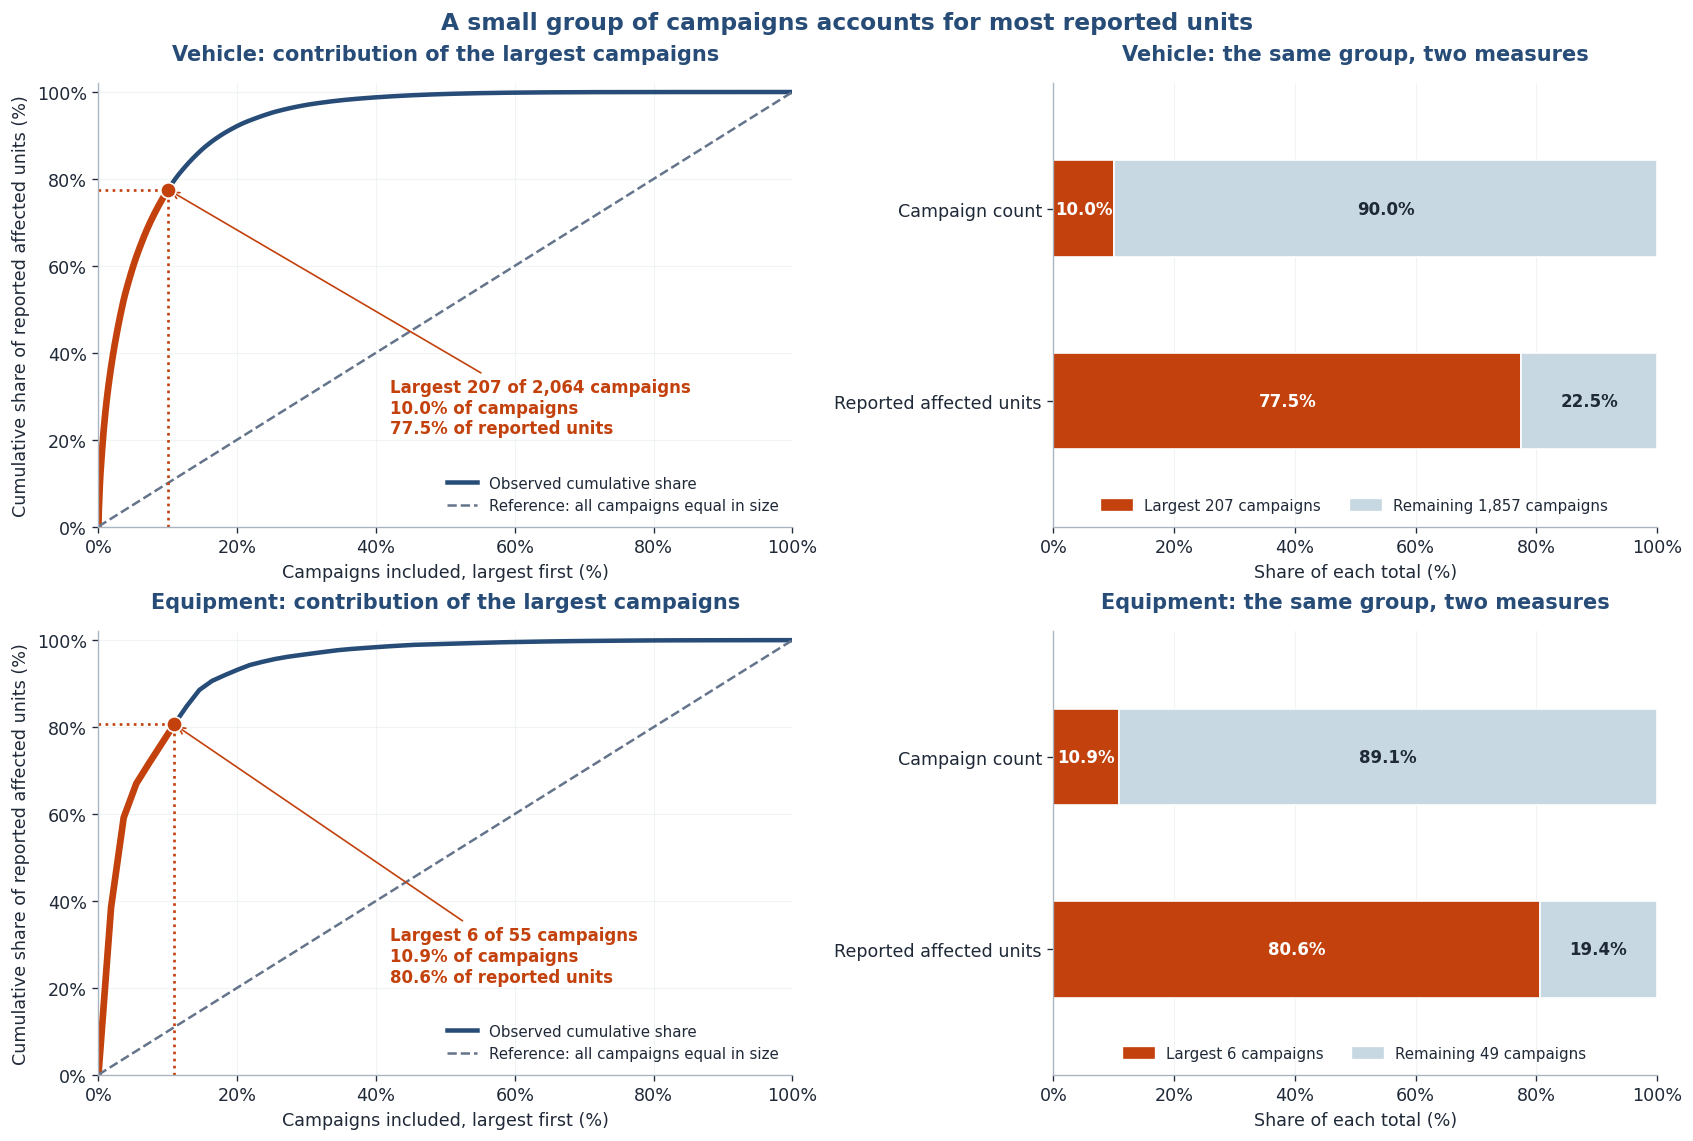

In [9]:
# 3. Show the same selected group using two clear views.
TOP_COLOR = COLORS["accent"]       # Dark orange: selected largest campaigns.
REST_COLOR = COLORS["light"]      # Light blue: all remaining campaigns.
CURVE_COLOR = COLORS["navy"]     # Navy: cumulative affected-unit share.
REFERENCE_COLOR = COLORS["muted"]

fig, axes = plt.subplots(
    len(curves), 2,
    figsize=(14, 4.7 * len(curves)),
    squeeze=False,
    layout="constrained",
    gridspec_kw={"width_ratios": [1.15, 1]},
)

for row, (category, (x, y, top_n)) in enumerate(curves.items()):
    name = q2_names[category]
    n = len(x) - 1
    campaign_share = x[top_n]
    unit_share = y[top_n]
    ax_curve, ax_bars = axes[row]

    # LEFT: cumulative concentration curve. Every plotted value is empirical.
    ax_curve.plot(
        x, y, color=CURVE_COLOR, linewidth=2.7,
        label="Observed cumulative share",
    )
    ax_curve.plot(
        x[:top_n + 1], y[:top_n + 1],
        color=TOP_COLOR, linewidth=4,
    )
    ax_curve.plot(
        [0, 100], [0, 100], color=REFERENCE_COLOR,
        linestyle="--", linewidth=1.5,
        label="Reference: all campaigns equal in size",
    )
    ax_curve.vlines(
        campaign_share, 0, unit_share,
        color=TOP_COLOR, linestyle=":", linewidth=1.6,
    )
    ax_curve.hlines(
        unit_share, 0, campaign_share,
        color=TOP_COLOR, linestyle=":", linewidth=1.6,
    )
    ax_curve.scatter(
        campaign_share, unit_share, s=85,
        color=TOP_COLOR, edgecolor="white", zorder=5,
    )
    ax_curve.annotate(
        f"Largest {top_n:,} of {n:,} campaigns\n"
        f"{campaign_share:.1f}% of campaigns\n"
        f"{unit_share:.1f}% of reported units",
        xy=(campaign_share, unit_share),
        xytext=(0.42, 0.21), textcoords="axes fraction",
        fontsize=10, color=TOP_COLOR, fontweight="bold",
        arrowprops={"arrowstyle": "->", "color": TOP_COLOR},
    )
    ax_curve.set(
        title=f"{name}: contribution of the largest campaigns",
        xlabel="Campaigns included, largest first (%)",
        ylabel="Cumulative share of reported affected units (%)",
        xlim=(0, 100), ylim=(0, 102),
    )
    ax_curve.xaxis.set_major_formatter(PercentFormatter(100))
    ax_curve.yaxis.set_major_formatter(PercentFormatter(100))
    ax_curve.grid(alpha=0.15)
    ax_curve.legend(loc="lower right", frameon=False, fontsize=9)

    # RIGHT: orange always represents the SAME selected campaigns.
    # Bar 1 measures their share of campaign COUNT.
    # Bar 2 measures their share of summed affected UNITS.
    selected_shares = [campaign_share, unit_share]
    remaining_shares = [100 - campaign_share, 100 - unit_share]

    ax_bars.barh(
        [0, 1], selected_shares, height=0.50,
        color=TOP_COLOR, edgecolor="white",
    )
    ax_bars.barh(
        [0, 1], remaining_shares, left=selected_shares,
        height=0.50, color=REST_COLOR, edgecolor="white",
    )

    for position, (selected, remaining) in enumerate(
        zip(selected_shares, remaining_shares)
    ):
        for left, width, text_color in [
            (0, selected, "white"),
            (selected, remaining, COLORS["ink"]),
        ]:
            if width >= 6:
                ax_bars.text(
                    left + width / 2, position, f"{width:.1f}%",
                    ha="center", va="center", fontsize=10,
                    fontweight="bold", color=text_color,
                )

    ax_bars.set(
        title=f"{name}: the same group, two measures",
        xlabel="Share of each total (%)", xlim=(0, 100),
        yticks=[0, 1],
        yticklabels=["Campaign count", "Reported affected units"],
        ylim=(1.65, -0.65),
    )
    ax_bars.xaxis.set_major_formatter(PercentFormatter(100))
    ax_bars.set_axisbelow(True)
    ax_bars.grid(axis="x", alpha=0.15)
    ax_bars.legend(
        handles=[
            Patch(color=TOP_COLOR, label=f"Largest {top_n:,} campaigns"),
            Patch(color=REST_COLOR, label=f"Remaining {n - top_n:,} campaigns"),
        ],
        loc="lower center", frameon=False, ncol=2, fontsize=9,
    )

    for ax in (ax_curve, ax_bars):
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "A small group of campaigns accounts for most reported units",
    fontsize=14, fontweight="semibold", color=CURVE_COLOR,
)
plt.show()

### <span style="color:#0F766E;">Answer 02 · A small group of campaigns accounts for most reported units</span>

The largest **207 of 2,064 positive-size vehicle campaigns** account for **77.5% of reported affected units**. Equipment campaigns show a similar concentration: the largest **6 of 55** account for **80.6%**.

These groups represent **10.0%** and **10.9%** of their respective campaign counts because the calculation selects whole campaigns. The finding shows why unusually large campaigns deserve separate attention alongside measures of typical size.

These totals sum reported campaign populations. The same vehicle may appear in more than one campaign, so the totals are not counts of unique vehicles, completed repairs, or sales.

### <span style="color:#0F766E;">Examples from the largest vehicle campaigns</span>

The three largest vehicle campaigns illustrate the upper end of the distribution. The population shown belongs to the whole campaign; the associated brands identify links without dividing that population among them.

In [10]:
# Examples count each vehicle campaign once.
if "V" in ranked_by_category:
    example_columns = [
        column for column in ["CAMPNO", "report_date", "potential_units"]
        if column in q2_data.columns
    ]
    largest_vehicle = ranked_by_category["V"].head(3)[example_columns].copy()
    if "campaign_brands" in globals():
        linked_brands = (
            campaign_brands[["CAMPNO", "brand"]]
            .dropna().drop_duplicates()
            .groupby("CAMPNO")["brand"]
            .agg(lambda values: ", ".join(sorted(values)))
        )
        largest_vehicle["Associated brands"] = largest_vehicle["CAMPNO"].map(
            linked_brands
        )
    show_table(largest_vehicle.reset_index(drop=True), index=False)

CAMPNO,report_date,potential_units,Associated brands
15V320000,2015-05-28,"6,281,043","ACURA, HONDA"
15V370000,2015-06-15,"3,498,481","ACURA, HONDA"
16V244000,2016-04-26,"3,296,947","INFINITI, NISSAN"


### <span style="color:#0F766E;">A question prompted by the finding · When does recall traffic add business or strain capacity?</span>

**Under what conditions do large recall campaigns create more dealership business than they displace, and how do visit timing and available capacity change that balance?**

The largest approximately **10%** of positive-size vehicle campaigns account for **77.5%** of reported affected units. That concentration makes a small group of campaigns a useful starting point for investigating dealership activity.

- **A possible opportunity:** recall visits may bring in new customers or customers who have not visited recently. Some may need tires or maintenance, creating opportunities for purchases and future service relationships.
- **The capacity trade-off:** if recall work arrives when service capacity is limited, other customers may face longer waits. Those with urgent tire or repair needs might choose another provider. Added sales and displaced business could occur during the same campaign.
- **What I would distinguish:** additional purchases from purchases that would have happened anyway, and business postponed from business lost to another provider. A visit does not automatically produce a purchase or a lost sale. The balance may depend on how many affected customers visit each location, whether appointments cluster, and the repair hours required.
- **How I would investigate it:** connect campaigns to dealership recall visits, repair hours, appointment availability, customer histories, and tire and parts purchases. Compare changes around major campaigns with similar dealerships or periods experiencing less recall activity, accounting for seasonality and local demand. Customer follow-up could help establish whether cancelled or unbooked appointments became later visits or purchases elsewhere.
- **Why it matters:** the results could inform staffing, appointment capacity, and parts preparation, while testing whether those decisions improve customer access and business outcomes.

This is a hypothesis prompted by the concentration finding. The recall dataset alone does not establish effects on dealership visits, sales, or capacity.

## <span style="color:#274C77;">Question 03 · Does a learned model improve next month's recall-campaign forecast?</span>

**Why I chose it.** Historical patterns become more useful for planning if they help anticipate later activity. I test whether a learned model improves on a simple historical average.

**Target and comparison.** Predict the number of unique campaigns reported next month across the selected brands. Each `CAMPNO` is counted once, including campaigns with zero or missing affected populations. I compare the **previous 12-month average** with a **shallow random forest** using past counts, past averages, and calendar month.

| Period | Role |
|:--|:--|
| **2013–2016** | Initial training history |
| **2017–2019** | Validation |
| **2020–2022** | Final evaluation |

An earlier comparison on the validation period informed the two methods retained here. Their settings remain fixed during final evaluation. Each forecast uses only earlier months; once the target month has occurred, its observed count becomes available for the next forecast.

**Metric:** mean absolute error (**MAE**), measured in campaigns per month; lower is better. This is a retrospective, one-month-ahead evaluation using the supplied historical snapshot.

### <span style="color:#0F766E;">3A · Build the monthly target</span>

The study period provides **120 monthly observations**. Months without campaigns count as zero, assuming the extract covers the full period. The monthly counts must reconcile to the **2,120 unique campaigns** in the study.

In [11]:
q3 = analysis_recalls[["CAMPNO", "report_date"]].copy()
q3["report_date"] = pd.to_datetime(q3["report_date"], errors="raise")
assert q3["CAMPNO"].notna().all() and q3["CAMPNO"].is_unique
assert q3["report_date"].notna().all()

calendar = pd.date_range("2013-01-01", "2022-12-01", freq="MS")
monthly = (
    q3.set_index("report_date")["CAMPNO"].resample("MS").nunique()
    .reindex(calendar, fill_value=0)
    .rename("campaign_count").to_frame().rename_axis("month")
)
y = monthly["campaign_count"].astype(float)
assert len(y) == 120 and int(y.sum()) == len(q3)
print(f"{len(y)} months | {int(y.sum()):,} unique campaigns")

120 months | 2,120 unique campaigns


### <span style="color:#0F766E;">3B · Forecast each month from earlier observations</span>

The forest uses counts from **1, 2, 3, and 12 months earlier**, averages over the preceding **3 and 12 months**, and calendar-month features. Every rolling average begins with a one-month shift.

Limiting tree depth and requiring at least six training observations per leaf restrict model complexity for this small dataset. The model is refitted as more history becomes available, while its settings stay fixed.

In [12]:
def predict_month(series, month):
    history = series.loc[series.index < month]
    # Add the target month without revealing its outcome.
    extended = history.reindex(
        history.index.append(pd.DatetimeIndex([month]))
    )
    X = pd.DataFrame({
        f"lag_{lag}": extended.shift(lag) for lag in (1, 2, 3, 12)
    })
    for window in (3, 12):
        X[f"mean_{window}"] = extended.shift(1).rolling(window).mean()
    angle = 2 * np.pi * (X.index.month - 1) / 12
    X["month_sin"], X["month_cos"] = np.sin(angle), np.cos(angle)

    train = X.loc[history.index].dropna().index
    model = RandomForestRegressor(
        n_estimators=300, max_depth=3, min_samples_leaf=6,
        random_state=42, n_jobs=1,
    )
    model.fit(X.loc[train], history.loc[train])
    return {
        "baseline": float(history.tail(12).mean()),
        "model": float(model.predict(X.loc[[month]])[0]),
    }

months = y.loc["2017":"2022"].index
predictions = pd.DataFrame(
    [predict_month(y, month) for month in months], index=months
)
predictions["actual"] = y.loc[months]

### <span style="color:#0F766E;">3C · Compare prediction errors</span>

I report validation and final evaluation separately to see whether an earlier advantage carries forward. MAE expresses the average absolute miss in **campaigns per month**, making the comparison easy to interpret.

In [13]:
validation = predictions.loc["2017":"2019"]
forecasts = predictions.loc["2020":"2022"].copy()
evaluation_months = forecasts.index
assert len(validation) == len(forecasts) == 36
assert forecasts[["baseline", "model"]].notna().all().all()

def mae(frame):
    return frame[["baseline", "model"]].sub(frame["actual"], axis=0).abs().mean()

results = pd.DataFrame({
    "Validation MAE (2017–2019)": mae(validation),
    "Evaluation MAE (2020–2022)": mae(forecasts),
}).rename(index={
    "baseline": "Previous 12-month average",
    "model": "Shallow random forest",
})
show_table(results, decimals=2)

errors = mae(forecasts)
change = 100 * (errors["model"] / errors["baseline"] - 1)
print(f"Forest MAE change versus baseline: {change:+.1f}% (lower is better)")

,Validation MAE (2017–2019),Evaluation MAE (2020–2022)
Previous 12-month average,4.64,4.57
Shallow random forest,4.58,4.72


Forest MAE change versus baseline: +3.2% (lower is better)


### <span style="color:#0F766E;">3D · Compare the forecasts with observed activity</span>

The chart shows the **2020–2022 final evaluation period**. It complements the error table by showing how each forecast responds to monthly fluctuations and where larger misses occur.

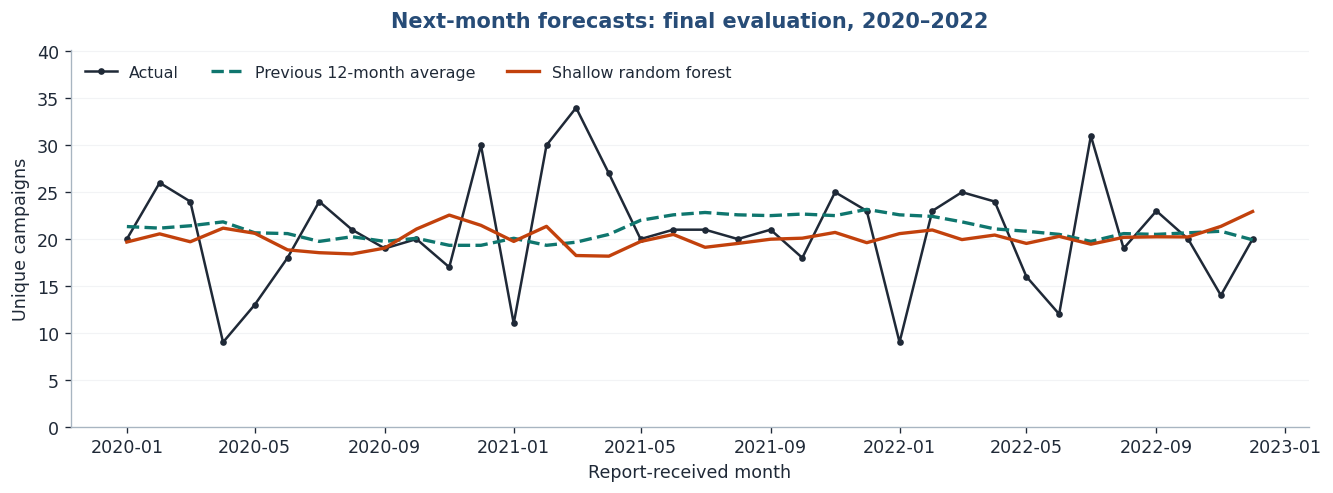

In [14]:
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.plot(forecasts.index, forecasts["actual"], color=COLORS["ink"],
        marker="o", markersize=3, linewidth=1.5, label="Actual")
ax.plot(forecasts.index, forecasts["baseline"], color=COLORS["teal"],
        linewidth=2, linestyle="--", label="Previous 12-month average")
ax.plot(forecasts.index, forecasts["model"], color=COLORS["accent"],
        linewidth=2, label="Shallow random forest")
ax.set(title="Next-month forecasts: final evaluation, 2020–2022",
       xlabel="Report-received month", ylabel="Unique campaigns",
       ylim=(0, forecasts[["actual", "baseline", "model"]].max().max() * 1.18))
ax.legend(frameon=False, ncol=3, loc="upper left")
ax.grid(axis="y", alpha=0.15)
plt.show()

### <span style="color:#0F766E;">Answer 03 · The tested forest did not improve on the historical average</span>

The forest's small validation advantage did not carry into final evaluation. Across **36 monthly forecasts in 2020–2022**, its MAE was **4.72 campaigns**, compared with **4.57** for the previous 12-month average: **3.2% higher error**.

Historical averages provide a rough guide to next month's activity, but the tested forest did not improve that guide. I would retain the simple average for this comparison. The result applies to these one-month-ahead forecasts, selected brands, and historical period; it does not establish that campaign counts are universally unpredictable.

## <span style="color:#274C77;">What I take from the analysis</span>

| Question | Main finding | Planning implication |
|:--|:--|:--|
| **01 · Frequency and size** | Mercedes has **387 vehicle campaigns**, with a median population of **550**; Lexus has **47**, with a median of **87,060**. | Track campaign arrivals and typical size separately. |
| **02 · Concentration** | The largest approximately **10%** of positive-size vehicle campaigns account for **77.5%** of reported affected units. | Give exceptional campaigns attention alongside typical campaign activity. |
| **03 · Forecasting** | The historical average has evaluation MAE **4.57**, compared with **4.72** for the tested random forest. | Retain the simple benchmark for this comparison. |

**Practical limits.** Reported campaigns and affected populations describe potential exposure. The extract does not measure dealership appointments, completed repairs, tire or parts purchases, or lost sales. Shared campaign populations are not allocated to individual brands, and populations can overlap across campaigns. The business questions raised above would require dealership data to test.

### <span style="color:#0F766E;">Final reconciliation</span>

These checks confirm that the campaign, brand, monthly, and forecast totals agree across the analysis.

In [15]:
# Reconcile the campaign, brand, monthly, and forecast views.
assert raw["CAMPNO"].nunique() >= len(campaigns)
assert campaigns["CAMPNO"].is_unique
assert analysis_recalls["CAMPNO"].is_unique
assert not campaign_brands.duplicated(["CAMPNO", "brand"]).any()
assert brand_campaigns["brand"].nunique() == len(selected_brands)
assert len(brand_campaigns) == brand_summary["all_campaigns"].sum()
assert monthly["campaign_count"].sum() == len(analysis_recalls)
assert len(forecasts) == 36 and forecasts.index.is_monotonic_increasing
assert forecasts[["baseline", "model"]].notna().all().all()
print("Passed: campaign keys, brand links, monthly totals, and forecast coverage.")

Passed: campaign keys, brand links, monthly totals, and forecast coverage.


## <span style="color:#274C77;">Sources and reproducibility</span>

**Sources.** The analysis uses the supplied NHTSA `FLAT_RCL.txt` historical extract and its `RCL.txt` data dictionary. The study covers the assignment's 20 selected brands during **2013–2022**, using `RCDATE` for the reporting timeline.

**To rerun.** Place `FLAT_RCL.txt` and `RCL.txt` in a `data` folder beside this notebook, or beside the notebook itself. Install the required packages if needed:

```bash
python -m pip install jupyterlab pandas numpy matplotlib scikit-learn ipython
```

Open the notebook in **JupyterLab**, restart the kernel, and run all cells in order. The setup cell prints the main package versions; the checks reconcile campaign keys, category counts, monthly totals, and forecast coverage.

**Scope limitations.** The explicit brand lookup has not been established as an exhaustive alias audit. The retrospective forecasting evaluation also does not reconstruct publication delays or later revisions at each historical forecast date.

### <span style="color:#0F766E;">How I used AI</span>

I used **ChatGPT** to help develop the analysis structure, generate and debug portions of the Python and SQL, revise charts, explain forecasting choices, and polish the presentation. I guided the questions and reviewed whether the outputs matched the intended comparisons.

I challenged the original bell-curve graphic because it showed campaign frequency rather than affected-unit concentration. That led to the empirical concentration charts in Question 02. I also narrowed Question 03 to a focused comparison between a historical average and a random forest.

Verification was **AI-assisted** and included checking campaign keys, reconciling counts, reviewing population aggregation, and rerunning the calculations against the supplied files. The resulting checks and outputs are retained in the notebook.

---

**Thank you for taking the time to review my analysis.** 